# FoodPrice AI : analyse exploratoire des données (EDA)

**Projet intégrateur, science des données.** Responsable : personne 1 (Data Analyst, analyse métier et exploration).

Ce notebook présente le contexte métier, décrit le jeu de données des prix alimentaires au Bénin, contrôle sa qualité, résume ses statistiques et visualise l'évolution des prix par produit, marché et département. Il se termine par les conclusions métier et les recommandations transmises à la personne 2 pour la modélisation.

**Sommaire**

1. Contexte et problématique métier
2. Chargement des données
3. Structure du jeu de données
4. Qualité des données : manquants, doublons, incohérences
5. Statistiques descriptives
6. Valeurs extrêmes
7. Visualisations
   - 7.1 Couverture temporelle
   - 7.2 Évolution des prix
   - 7.3 Saisonnalité
   - 7.4 Comparaison entre produits
   - 7.5 Comparaison entre marchés
   - 7.6 Comparaison entre départements
8. Ce qui explique le prix
9. Conclusions métier et recommandations

## 1. Contexte et problématique métier

**Contexte.** Au Bénin, l'alimentation représente une part importante des dépenses des ménages. Les prix des denrées de base (maïs, riz, gari, igname, haricot, huile) varient selon la saison, la localisation du marché et la conjoncture régionale et internationale. Le Programme alimentaire mondial (PAM / WFP) collecte chaque mois les prix observés sur les marchés du pays et les publie sur la plateforme HDX.

**Problématique.** Comment connaître et anticiper le prix d'un produit alimentaire sur un marché donné, à une date donnée ?

**Utilisateurs visés.**
- Les ménages et commerçants, pour savoir si un prix est normal ou anormal.
- Les ONG et services publics de sécurité alimentaire, pour repérer les hausses localisées.
- Les analystes, pour comparer marchés et départements à produit égal.

**Objectif data.** Construire un modèle de régression qui estime `price` (en francs CFA, XOF) à partir du produit, de l'unité, du type de prix, du marché, de sa localisation et de la date. L'EDA doit établir ce que les données permettent réellement, et sous quelles précautions.

**Précautions de lecture fixées dès le départ.**
- Un prix n'a de sens qu'avec son produit, son unité et son type de prix (détail ou gros).
- `usdprice` est une conversion de `price` : il ne peut pas servir de variable explicative.
- Les valeurs extrêmes sont examinées, jamais supprimées automatiquement.

## 2. Chargement des données

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

# Le notebook peut être lancé depuis notebooks/ ou depuis la racine du dépôt
ROOT = Path.cwd()
while not (ROOT / "data" / "raw").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RAW_DIR = ROOT / "data" / "raw"

files = sorted(RAW_DIR.glob("*.parquet"))
print("Fichiers trouvés :", [f.name for f in files])

frames = []
for f in files:
    part = pd.read_parquet(f)
    part["source_file"] = f.name.split("-")[0]  # 'train' ou 'test'
    frames.append(part)
raw = pd.concat(frames, ignore_index=True)
print("Dimensions :", raw.shape)
raw.head()

Fichiers trouvés : ['test-00000-of-00001.parquet', 'train-00000-of-00001.parquet']


Dimensions : (114412, 19)


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice,esa_source,esa_processed,source_file
0,2019-07-15,Atlantique,Ze,Sèdjè-Dénou,2776,6.72,2.38,vegetables and fruits,Oranges,360,KG,actual,Retail,XOF,110.00,0.19,HDX,2026-04-06,test
1,2023-03-15,Oueme,Dangbo,Dangbo,2766,6.59,2.55,vegetables and fruits,"Peppers (red, dry)",534,KG,actual,Retail,XOF,"4,038.46",6.65,HDX,2026-04-06,test
2,2023-02-15,Oueme,Dangbo,Hozin,2770,6.60,2.55,"meat, fish and eggs","Fish (fresh, silvi)",561,KG,actual,Retail,XOF,"1,266.67",2.08,HDX,2026-04-06,test
3,2025-11-15,Zou,Ouinhi,Dasso,2768,7.01,2.46,cereals and tubers,Sorghum,65,KG,actual,Retail,XOF,541.00,0.96,HDX,2026-04-06,test
4,2024-06-15,Littoral,Cotonou,Dantokpa,124,6.37,2.43,cereals and tubers,Wheat flour (imported),339,KG,actual,Retail,XOF,600.00,0.98,HDX,2026-04-06,test


Les deux fichiers fournis (`train` et `test`) ont les mêmes colonnes. Ils sont fusionnés pour l'analyse. La colonne `source_file` garde leur origine afin de vérifier plus loin comment le découpage a été fait.

## 3. Structure du jeu de données

In [2]:
info = pd.DataFrame({
    "type": raw.dtypes.astype(str),
    "valeurs_distinctes": raw.nunique(),
    "exemple": raw.iloc[0],
})
info

,type,valeurs_distinctes,exemple
date,datetime64[ns],254,2019-07-15 00:00:00
admin1,object,12,Atlantique
admin2,object,46,Ze
market,object,51,Sèdjè-Dénou
market_id,int64,51,2776
latitude,float64,48,6.72
longitude,float64,42,2.38
category,object,6,vegetables and fruits
commodity,object,53,Oranges
commodity_id,int64,53,360


**Dictionnaire des variables**

| Variable | Description | Rôle pour le projet |
|---|---|---|
| `date` | Mois de relevé (toujours le 15 du mois) | Variable temporelle, à décomposer en année et mois |
| `admin1` | Département (12 au Bénin) | Variable explicative géographique |
| `admin2` | Commune | Variable explicative géographique |
| `market`, `market_id` | Nom et identifiant du marché | Variable explicative, l'identifiant est redondant avec le nom |
| `latitude`, `longitude` | Coordonnées du marché | Variables explicatives numériques |
| `category` | Groupe de produits (céréales, légumes...) | Variable explicative |
| `commodity`, `commodity_id` | Nom et identifiant du produit | Variable explicative principale |
| `unit` | Unité de vente (KG ou L) | Indispensable pour interpréter le prix |
| `pricetype` | Prix de détail (`Retail`) ou de gros (`Wholesale`) | Indispensable pour interpréter le prix |
| `priceflag` | Statut du prix (observé, estimé...) | Contrôle qualité |
| `currency` | Devise du prix | Contrôle qualité |
| `price` | Prix en XOF par unité | **Variable cible** |
| `usdprice` | Prix converti en dollars | **À exclure** : dérivé de la cible, fuite de données |
| `esa_source`, `esa_processed` | Source et date de traitement des données | Métadonnées, sans valeur explicative |

In [3]:
for col in ["admin1", "category", "unit", "pricetype", "priceflag", "currency", "esa_source", "esa_processed"]:
    print(f"{col:15s}", raw[col].value_counts().to_dict())

admin1          {'Zou': 14412, 'Atlantique': 14234, 'Borgou': 12800, 'Oueme': 12647, 'Atakora': 11883, 'Collines': 11119, 'Plateau': 10220, 'Alibori': 7193, 'Donga': 7020, 'Couffo': 6751, 'Littoral': 3592, 'Mono': 2541}
category        {'cereals and tubers': 52277, 'vegetables and fruits': 30787, 'pulses and nuts': 18201, 'oil and fats': 7380, 'meat, fish and eggs': 5203, 'miscellaneous food': 564}
unit            {'KG': 108306, 'L': 6106}
pricetype       {'Retail': 114196, 'Wholesale': 216}
priceflag       {'actual': 114412}
currency        {'XOF': 114412}
esa_source      {'HDX': 114412}
esa_processed   {'2026-04-06': 114412}


In [4]:
print("Nombre de produits :", raw["commodity"].nunique())
print("Nombre de marchés  :", raw["market"].nunique())
print("Nombre de communes :", raw["admin2"].nunique())
raw.groupby("category")["commodity"].unique().apply(lambda v: ", ".join(sorted(v))).to_frame("produits")

Nombre de produits : 53
Nombre de marchés  : 51
Nombre de communes : 46


,produits
category,
cereals and tubers,"Cassava (cossette), Cassava (fresh), Cassava f..."
"meat, fish and eggs","Fish (fresh, silvi), Fish (tilapia), Shrimps"
miscellaneous food,Snail
oil and fats,"Oil (groundnut), Oil (palm nut), Oil (palm)"
pulses and nuts,"Beans (black), Beans (red), Beans (white), Gro..."
vegetables and fruits,"Cabbage, Carrots, Coconut (dried), Leafy veget..."


**Lecture.** Le jeu contient environ 114 000 relevés mensuels, 53 produits répartis en 6 catégories, 51 marchés et 12 départements. Les céréales et tubercules dominent. Presque tous les prix sont au détail et au kilogramme. Seules les huiles sont vendues au litre, et les prix de gros ne concernent qu'un marché frontalier.

Plusieurs colonnes ne portent aucune information : `currency`, `priceflag`, `esa_source` et `esa_processed` ont une seule valeur. Certains produits existent sous deux libellés proches, par exemple `Maize` et `Maize (white)`, ou `Yam` et `Yam (white)`. Ils sont conservés tels quels, car rien ne prouve qu'il s'agit du même produit.

## 4. Qualité des données : manquants, doublons, incohérences

### 4.1 Valeurs manquantes

In [5]:
missing = raw.isna().sum().to_frame("manquants")
missing["pourcentage"] = 100 * missing["manquants"] / len(raw)
missing

,manquants,pourcentage
date,0,0.00
admin1,0,0.00
admin2,0,0.00
market,0,0.00
market_id,0,0.00
latitude,0,0.00
longitude,0,0.00
category,0,0.00
commodity,0,0.00
commodity_id,0,0.00


### 4.2 Doublons

In [6]:
KEY = ["date", "market", "commodity", "unit", "pricetype"]
print("Doublons exacts               :", raw.duplicated().sum())
print("Doublons sur la clé de relevé :", raw.duplicated(subset=KEY).sum())

Doublons exacts               : 0
Doublons sur la clé de relevé : 0


La clé de relevé est la combinaison date, marché, produit, unité et type de prix. Elle est unique : chaque ligne correspond à un seul prix pour un produit, un marché et un mois.

### 4.3 Cohérences

In [7]:
checks = {
    "Prix nuls ou négatifs": int((raw["price"] <= 0).sum()),
    "Dates hors du 15 du mois": int((raw["date"].dt.day != 15).sum()),
    "Marchés avec plusieurs communes": int((raw.groupby("market")["admin2"].nunique() > 1).sum()),
    "Marchés avec plusieurs départements": int((raw.groupby("market")["admin1"].nunique() > 1).sum()),
    "Marchés avec plusieurs coordonnées": int((raw.groupby("market")[["latitude", "longitude"]].nunique() > 1).any(axis=1).sum()),
    "Noms de marché avec plusieurs identifiants": int((raw.groupby("market")["market_id"].nunique() > 1).sum()),
    "Produits avec plusieurs identifiants": int((raw.groupby("commodity")["commodity_id"].nunique() > 1).sum()),
    "Produits vendus dans plusieurs unités": int((raw.groupby("commodity")["unit"].nunique() > 1).sum()),
    "Produits rattachés à plusieurs catégories": int((raw.groupby("commodity")["category"].nunique() > 1).sum()),
}
pd.Series(checks, name="nombre").to_frame()

,nombre
Prix nuls ou négatifs,0
Dates hors du 15 du mois,0
Marchés avec plusieurs communes,0
Marchés avec plusieurs départements,0
Marchés avec plusieurs coordonnées,0
Noms de marché avec plusieurs identifiants,0
Produits avec plusieurs identifiants,0
Produits vendus dans plusieurs unités,0
Produits rattachés à plusieurs catégories,0


In [8]:
# usdprice = price / taux de change du mois : le ratio doit être le même pour tous les produits d'un mois
# On écarte les très petits montants en dollars, dont l'arrondi à 2 décimales fausse le ratio
big = raw["usdprice"] >= 1
rate = raw.loc[big, "price"] / raw.loc[big, "usdprice"]
monthly_rate = rate.groupby(raw.loc[big, "date"]).transform("median")
gap = (rate / monthly_rate - 1).abs()
print("Taux XOF/USD médian mensuel :", round(monthly_rate.min()), "à", round(monthly_rate.max()))
print(f"Lignes dont le ratio s'écarte de plus de 2 % du taux du mois : {(gap > 0.02).sum()} sur {len(rate)}")

Taux XOF/USD médian mensuel : 419 à 685
Lignes dont le ratio s'écarte de plus de 2 % du taux du mois : 2 sur 42240


Le ratio entre `price` et `usdprice` est le même pour toutes les lignes d'un mois : c'est le taux de change du mois. Seules quelques lignes isolées s'en écartent. Sur les très petits montants, l'arrondi de `usdprice` à deux décimales fausse le ratio, d'où leur exclusion du calcul. Cela confirme que `usdprice` est un simple calcul à partir de la cible : l'utiliser comme variable explicative reviendrait à donner la réponse au modèle.

### 4.4 Le découpage train / test fourni

In [9]:
split = raw.groupby("source_file")["date"].agg(["size", "min", "max"])
split["part"] = split["size"] / split["size"].sum()
print(split)
print("\nCombinaisons de la clé présentes dans les deux fichiers :",
      len(raw[raw.source_file == "train"][KEY].merge(raw[raw.source_file == "test"][KEY])))

share = (raw.groupby(raw["date"].dt.year)["source_file"]
            .apply(lambda s: (s == "test").mean()).rename("part_test"))
share.loc[2019:].to_frame().T

              size        min        max  part
source_file                                   
test         22883 2002-01-15 2026-02-15  0.20
train        91529 2002-01-15 2026-02-15  0.80

Combinaisons de la clé présentes dans les deux fichiers : 0


date,2019,2020,2021,2022,2023,2024,2025,2026
part_test,0.20,0.20,0.20,0.20,0.20,0.20,0.20,0.20


**Constat important.** Le fichier `test` représente 20 % des lignes, tirées au hasard sur toute la période. Les deux fichiers couvrent les mêmes dates et la part de test est la même chaque année.

Ce découpage aléatoire ne simule pas l'usage réel du modèle, qui doit estimer des prix futurs à partir du passé. Avec lui, le modèle verrait le même marché et le même produit le mois précédent et le mois suivant, et ses scores seraient trop optimistes. **Recommandation : fusionner les deux fichiers et refaire un découpage temporel** (voir section 9).

**Bilan qualité.** Les données sont propres sur le plan technique : aucune valeur manquante, aucun doublon, aucun prix négatif, des référentiels de marchés et de produits cohérents. Les points à surveiller sont le découpage fourni, les doublons de libellés de produits et quelques prix extrêmes étudiés en section 6.

## 5. Statistiques descriptives

In [10]:
df = raw.copy()
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["log_price"] = np.log(df["price"])

df["price"].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).to_frame("price (XOF)")

,price (XOF)
count,"114,412.00"
mean,719.04
std,"1,071.23"
min,3.00
1%,90.00
5%,145.20
25%,300.00
50%,483.33
75%,738.26
95%,"1,700.00"


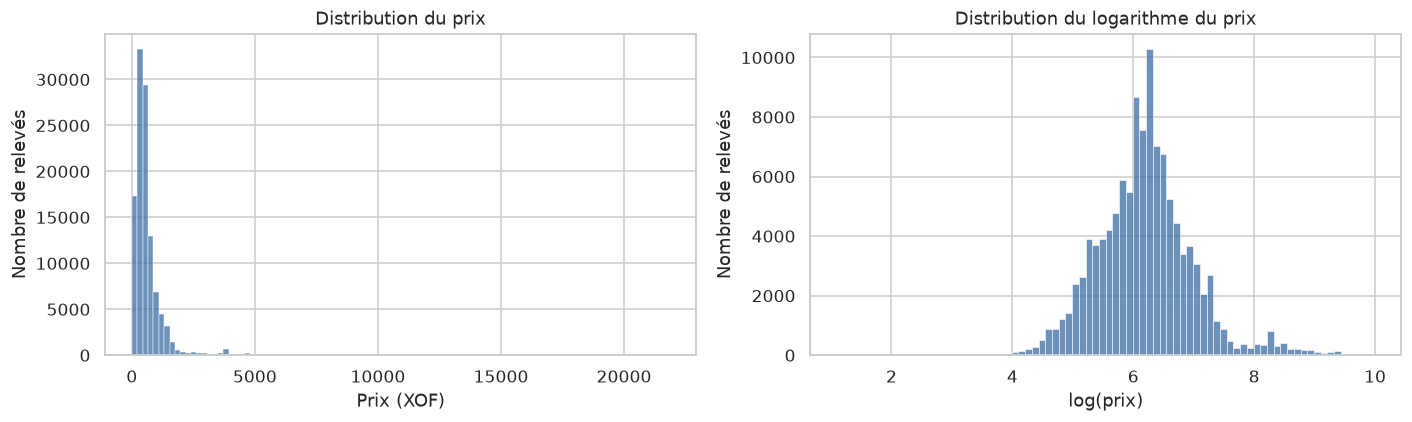

Asymétrie du prix : 6.98   Asymétrie de log(prix) : 0.56


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["price"], bins=100, ax=axes[0], color="#3b6ea5")
axes[0].set(title="Distribution du prix", xlabel="Prix (XOF)", ylabel="Nombre de relevés")
sns.histplot(df["log_price"], bins=80, ax=axes[1], color="#3b6ea5")
axes[1].set(title="Distribution du logarithme du prix", xlabel="log(prix)", ylabel="Nombre de relevés")
plt.tight_layout(); plt.show()
print(f"Asymétrie du prix : {df['price'].skew():.2f}   Asymétrie de log(prix) : {df['log_price'].skew():.2f}")

La distribution du prix est très asymétrique : la plupart des produits coûtent quelques centaines de francs, quelques-uns plusieurs milliers. Le logarithme rend la distribution presque symétrique. **Un modèle entraîné sur `log(prix)` sera plus stable.** C'est l'option `LOG_TARGET` prévue dans l'application.

In [12]:
by_cat = (df.groupby("category")["price"]
            .agg(releves="size", produits=lambda s: df.loc[s.index, "commodity"].nunique(),
                 moyenne="mean", mediane="median", minimum="min", maximum="max")
            .sort_values("mediane"))
by_cat

,releves,produits,moyenne,mediane,minimum,maximum
category,,,,,,
vegetables and fruits,30787,12,816.24,372.75,15.00,"21,843.59"
cereals and tubers,52277,27,468.44,425.53,3.00,"6,200.00"
pulses and nuts,18201,7,624.08,588.24,72.61,"3,846.00"
oil and fats,7380,3,"1,071.16","1,000.00",130.00,"3,800.00"
miscellaneous food,564,1,"1,639.12","1,232.25",267.00,"6,583.50"
"meat, fish and eggs",5203,3,"2,394.75","1,500.00",25.00,"18,947.00"


In [13]:
RECENT = df[df["year"] >= 2023]
by_prod = (RECENT.groupby(["category", "commodity", "unit"])["price"]
             .agg(releves="size", mediane="median", moyenne="mean", ecart_type="std"))
by_prod["coef_variation"] = by_prod["ecart_type"] / by_prod["moyenne"]
by_prod.sort_values("mediane")

releves  mediane  moyenne  ecart_type  coef_variation
category              commodity                     unit                                                       
cereals and tubers    Cassava (fresh)               KG        622   150.00   185.04      111.26            0.60
vegetables and fruits Oranges                       KG       1544   193.33   219.08      121.13            0.55
cereals and tubers    Maize (white)                 KG       1437   217.25   221.46       61.08            0.28
                      Maize (yellow)                KG       1411   227.00   239.08       94.77            0.40
                      Sweet potatoes                KG       1172   246.29   276.81      148.47            0.54
                      Rice (paddy)                  KG        366   250.00   573.99    1,013.26            1.77
vegetables and fruits Papaya                        KG       1015   250.00   270.41      147.09            0.54
cereals and tubers    Cassava (cossette)            KG        688   250.00   303.49      191.13            0.63
vegetables and fruits Leafy vegetables              KG       1476   256.45   284.03      132.88            0.47
cereals and tubers    Yam                           KG       1109   333.75   369.27      247.98            0.67
vegetables and fruits Lemons                        KG       1494   341.71   379.77      220.10            0.58
cereals and tubers    Taro                          KG        245   345.00   411.86      230.03            0.56
                      Cassava meal (gari)           KG       1677   357.14   374.14      105.56            0.28
                      Yam (yellow)                  KG        226   363.00   391.68      287.41            0.73
pulses and nuts       Soybeans                      KG       1567   363.50   369.08      110.36            0.30
vegetables and fruits Okra (fresh)                  KG       1560   371.00   401.24      197.33            0.49
cereals and tubers    Sorghum                       KG       1203   392.75   392.85      145.61            0.37
                      Sorghum (red)                 KG       1650   395.11   391.45      135.74            0.35
vegetables and fruits Coconut (dried)               KG       1265   405.00   432.67      202.58            0.47
cereals and tubers    Yam (white)                   KG       1074   406.41   435.44      275.10            0.63
                      Millet                        KG       1359   443.00   458.14      158.89            0.35
                      Cassava meal (gari, fine)     KG       1456   451.39   452.37      144.14            0.32
vegetables and fruits Tomatoes                      KG       1606   454.00   516.63      356.90            0.69
cereals and tubers    Rice (Broken, local)          KG        962   457.71   484.82      116.00            0.24
                      Cassava flour                 KG        728   472.00   565.98      292.39            0.52
                      Rice (milled, local)          KG        737   479.00   502.52      104.34            0.21
vegetables and fruits Onions                        KG       1605   483.00   513.21      251.94            0.49
cereals and tubers    Rice (local)                  KG       1083   492.25   533.65      133.85            0.25
vegetables and fruits Cabbage                       KG        912   500.34   581.68      308.81            0.53
                      Plantains                     KG        356   547.12   534.09      187.73            0.35
pulses and nuts       Beans (black)                 KG        482   567.43   568.10      207.16            0.36
                      Beans (red)                   KG       1395   595.75   641.83      245.94            0.38
cereals and tubers    Rice (imported)               KG       1544   598.25   593.16       96.18            0.16
                      Wheat                         KG       1035   600.00   609.11      178.98            0.29
                      Whea

**Lecture.** Le tableau porte sur 2023 à 2026 pour décrire les prix actuels. Les produits les moins chers au kilo sont le manioc frais, le maïs et les oranges. Les plus chers sont le poisson, le piment sec et surtout les crevettes. Le coefficient de variation mesure la dispersion relative : il est faible pour le riz importé, l'huile d'arachide et le poisson, dont les prix sont stables, et élevé pour certains tubercules et le riz paddy, très variables selon le marché et la saison.

## 6. Valeurs extrêmes

Un prix n'est extrême que par rapport aux autres prix du même produit. On calcule donc, pour chaque série produit, unité et type de prix, un score robuste sur `log(prix)` : écart à la médiane divisé par l'écart absolu médian (MAD). Un score supérieur à 3,5 en valeur absolue signale une valeur atypique.

In [14]:
grp = df.groupby(["commodity", "unit", "pricetype"])["log_price"]
med = grp.transform("median")
mad = grp.transform(lambda s: (s - s.median()).abs().median())
df["robust_z"] = (df["log_price"] - med) / (1.4826 * mad.replace(0, np.nan))

print("Relevés atypiques (|z| > 3,5) :", int((df["robust_z"].abs() > 3.5).sum()),
      f"soit {100 * (df['robust_z'].abs() > 3.5).mean():.2f} %")
print("Relevés très atypiques (|z| > 5) :", int((df["robust_z"].abs() > 5).sum()))

cols = ["date", "market", "admin1", "commodity", "unit", "price", "robust_z"]
print("\nPrix anormalement bas :")
display(df.nsmallest(8, "robust_z")[cols])
print("Prix anormalement hauts :")
display(df.nlargest(8, "robust_z")[cols])

Relevés atypiques (|z| > 3,5) : 967 soit 0.85 %
Relevés très atypiques (|z| > 5) : 142

Prix anormalement bas :


,date,market,admin1,commodity,unit,price,robust_z
77283,2023-06-15,Affamè,Oueme,Wheat,KG,5.00,-21.89
113324,2023-09-15,Karimama,Alibori,Fish (tilapia),KG,300.00,-12.06
107923,2023-08-15,Karimama,Alibori,Fish (tilapia),KG,303.00,-11.99
87443,2023-07-15,Karimama,Alibori,Fish (tilapia),KG,409.67,-9.86
49445,2021-01-15,Dantokpa,Littoral,Yam (yellow),KG,3.00,-9.72
60979,2025-05-15,Nikki,Borgou,"Peppers (red, dry)",KG,100.00,-9.54
65162,2025-03-15,Nikki,Borgou,"Peppers (red, dry)",KG,103.13,-9.46
78693,2020-07-15,Kalalé,Borgou,Shrimps,KG,25.00,-9.06


Prix anormalement hauts :


,date,market,admin1,commodity,unit,price,robust_z
91710,2021-10-15,Dantokpa,Littoral,Wheat flour (imported),KG,"1,800.00",6.44
1010,2025-09-15,Karimama,Alibori,Wheat flour (imported),KG,"1,700.00",6.14
6266,2024-04-15,Karimama,Alibori,Wheat flour (imported),KG,"1,700.00",6.14
13590,2023-01-15,Ouègbo,Atlantique,Wheat flour (imported),KG,"1,700.00",6.14
21886,2024-06-15,Karimama,Alibori,Wheat flour (imported),KG,"1,700.00",6.14
22559,2025-04-15,Karimama,Alibori,Wheat flour (imported),KG,"1,700.00",6.14
31697,2024-11-15,Karimama,Alibori,Wheat flour (imported),KG,"1,700.00",6.14
34078,2024-02-15,Karimama,Alibori,Wheat flour (imported),KG,"1,700.00",6.14


In [15]:
top = df.groupby("commodity")["robust_z"].apply(lambda s: (s.abs() > 3.5).sum()).sort_values(ascending=False).head(10)
top.to_frame("releves_atypiques")

,releves_atypiques
commodity,
Fish (tilapia),122
"Peppers (red, dry)",93
"Groundnuts (small, unshelled)",91
Beans (red),58
Rice (paddy),55
Cassava meal (gari),48
Wheat,40
Wheat flour (imported),36
Millet,35


**Lecture.** Moins de 1 % des relevés sont atypiques. Certains sont très probablement des erreurs de saisie ou d'unité, comme une igname jaune à 3 XOF le kilo, des crevettes à 25 XOF ou du blé à 5 XOF le kilo. D'autres peuvent être réels. Le tilapia de Karimama, sur le fleuve Niger, est par exemple durablement moins cher qu'ailleurs, ce qui évoque une pêche locale plutôt qu'une erreur.

Les scores élevés de la farine de blé importée ont une autre cause. Son prix est très stable, donc l'écart absolu médian est minuscule et un prix de 1 700 XOF suffit à produire un score élevé. Le score robuste doit donc toujours être lu avec le prix lui-même.

**Décision.** Ces valeurs ne sont pas supprimées dans le jeu de référence, conformément aux règles du projet. Elles sont signalées pour que la personne 2 puisse tester l'effet de leur retrait, et pour que la personne 4 les surveille lors des réentraînements.

## 7. Visualisations

### 7.1 Couverture temporelle

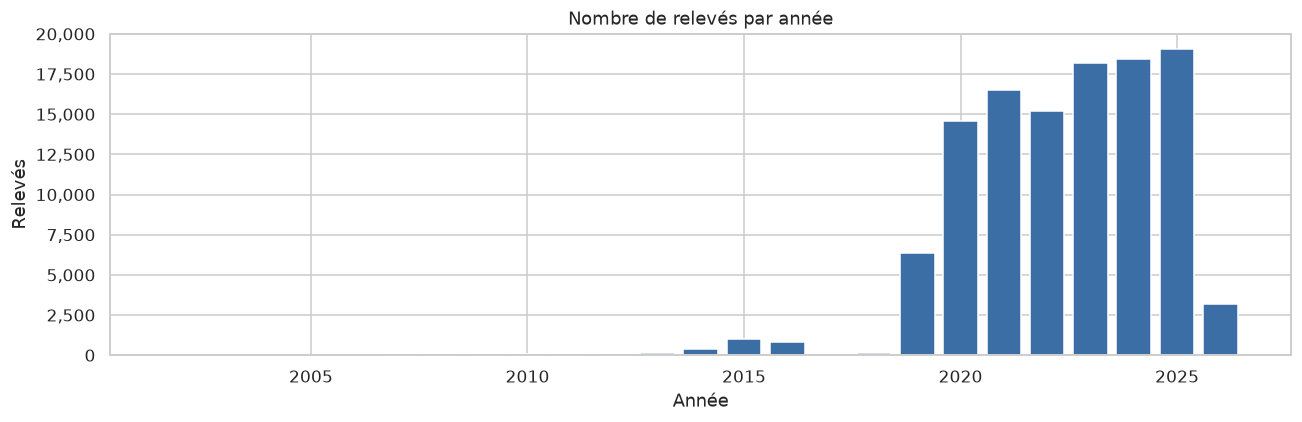

year,2002,2003,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
releves,2,33,40,14,60,76,66,77,79,92,122,370,977,817,38,117,6356,14565,16515,15168,18191,18413,19052,3172
marches,1,1,1,1,2,2,2,2,2,2,4,21,21,21,1,4,49,50,50,50,50,50,50,50
produits,2,4,5,4,7,7,7,7,7,7,7,7,7,7,5,5,30,49,49,49,52,52,52,52


In [16]:
yearly = df.groupby("year").agg(releves=("price", "size"),
                                marches=("market", "nunique"),
                                produits=("commodity", "nunique"))
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(yearly.index, yearly["releves"], color="#3b6ea5")
ax.set(title="Nombre de relevés par année", xlabel="Année", ylabel="Relevés")
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
plt.tight_layout(); plt.show()
yearly.T

Avant 2019, le suivi est très partiel : quelques dizaines à quelques centaines de relevés par an, sur peu de marchés. À partir de 2019, et surtout de 2020, le PAM suit environ 50 marchés et 50 produits chaque mois. 2026 ne contient que les premiers mois de l'année.

**Période d'étude retenue pour les comparaisons : 2019 à 2026**, soit plus de 97 % des relevés. Les années antérieures restent dans le jeu mais ne sont pas représentatives.

In [17]:
STUDY = df[df["year"] >= 2019].copy()
print("Relevés sur la période d'étude :", len(STUDY), f"({100 * len(STUDY) / len(df):.1f} %)")

Relevés sur la période d'étude : 111432 (97.4 %)


### 7.2 Évolution des prix

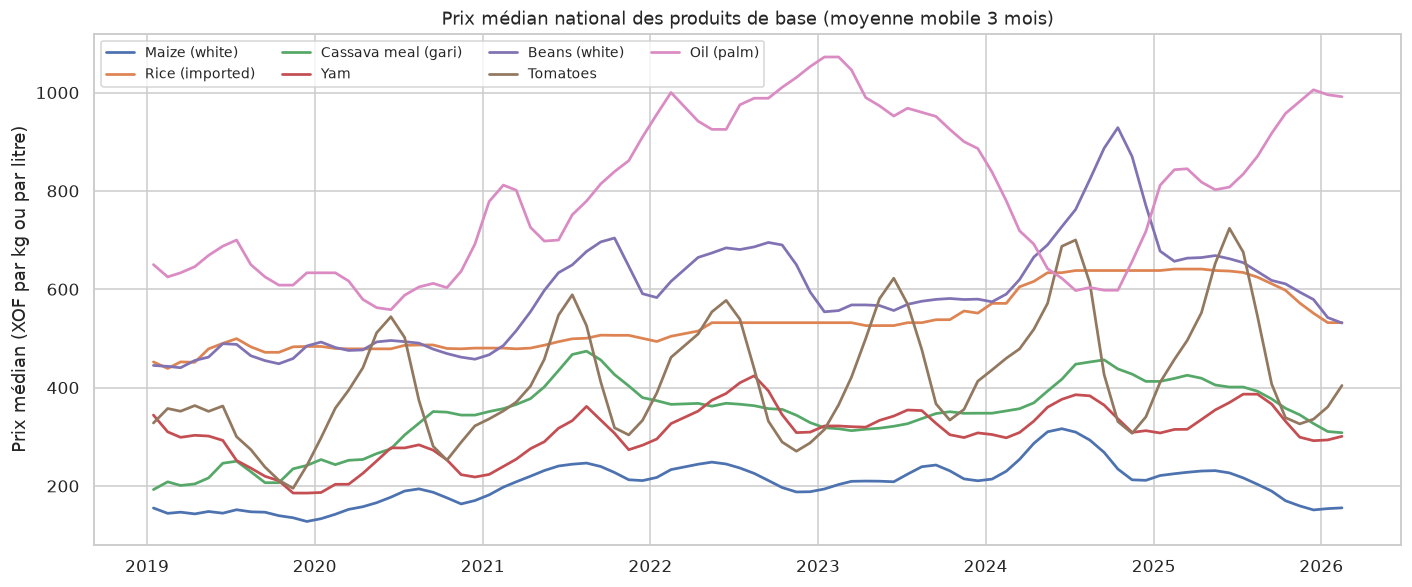

In [18]:
STAPLES = ["Maize (white)", "Rice (imported)", "Cassava meal (gari)", "Yam", "Beans (white)", "Tomatoes", "Oil (palm)"]
monthly = (STUDY[STUDY["commodity"].isin(STAPLES) & (STUDY["pricetype"] == "Retail")]
             .groupby(["date", "commodity"])["price"].median().unstack())

fig, ax = plt.subplots(figsize=(13, 5.5))
for c in STAPLES:
    ax.plot(monthly.index, monthly[c].rolling(3, min_periods=1).mean(), label=c, linewidth=1.8)
ax.set(title="Prix médian national des produits de base (moyenne mobile 3 mois)",
       xlabel="", ylabel="Prix médian (XOF par kg ou par litre)")
ax.legend(ncol=4, loc="upper left", fontsize=9)
plt.tight_layout(); plt.show()

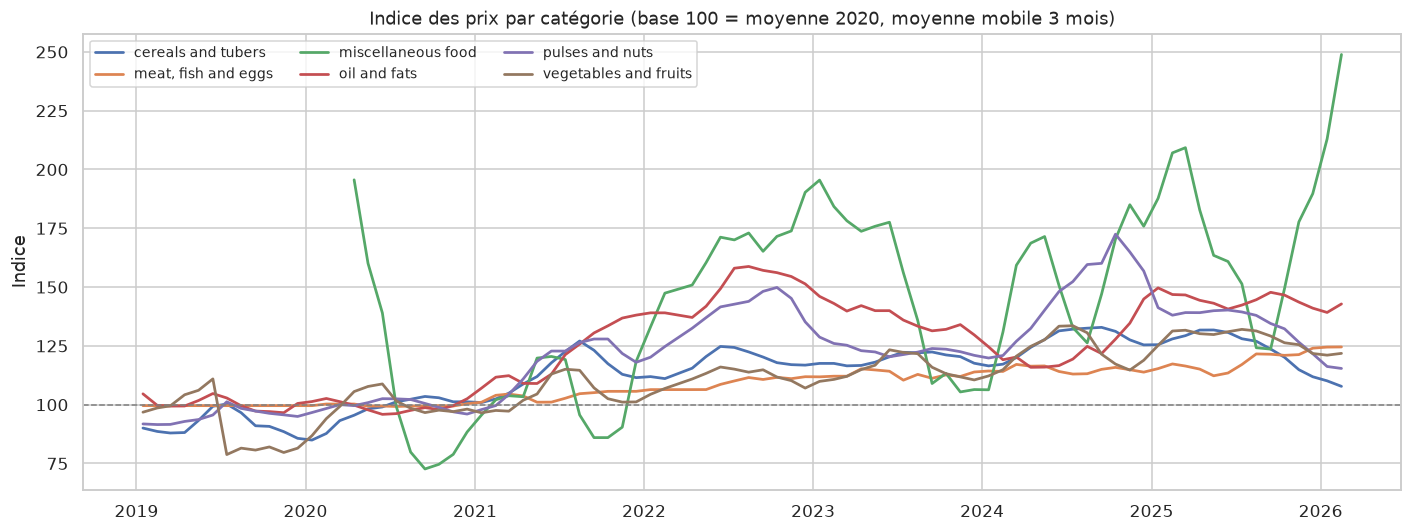

In [19]:
# Indice des prix par catégorie, base 100 = moyenne 2020.
# Pour chaque produit, on rapporte son prix médian mensuel à sa moyenne 2020, puis on fait la médiane par catégorie.
prod_month = STUDY.groupby(["date", "category", "commodity"])["price"].median().reset_index()
base = prod_month[prod_month["date"].dt.year == 2020].groupby("commodity")["price"].mean()
prod_month = prod_month[prod_month["commodity"].isin(base.index)]
prod_month["indice"] = 100 * prod_month["price"] / prod_month["commodity"].map(base)
cat_index = prod_month.groupby(["date", "category"])["indice"].median().unstack()

fig, ax = plt.subplots(figsize=(13, 5))
for c in cat_index.columns:
    ax.plot(cat_index.index, cat_index[c].rolling(3, min_periods=1).mean(), label=c, linewidth=1.8)
ax.axhline(100, color="grey", linestyle="--", linewidth=1)
ax.set(title="Indice des prix par catégorie (base 100 = moyenne 2020, moyenne mobile 3 mois)", ylabel="Indice")
ax.legend(ncol=3, fontsize=9)
plt.tight_layout(); plt.show()

In [20]:
annual = STUDY[STUDY["commodity"].isin(STAPLES)].groupby(["commodity", "year"])["price"].median().unstack()
annual["variation_2020_2025_%"] = 100 * (annual[2025] / annual[2020] - 1)
annual.round(0)

year,2019,2020,2021,2022,2023,2024,2025,2026,variation_2020_2025_%
commodity,,,,,,,,,
Beans (white),451.00,489.00,616.00,666.00,579.00,704.00,652.00,515.00,33.00
Cassava meal (gari),214.00,298.00,405.00,357.00,330.00,411.00,369.00,307.00,24.00
Maize (white),143.00,172.00,224.00,220.00,215.00,253.00,198.00,156.00,16.00
Oil (palm),638.00,600.00,825.00,"1,000.00",972.00,676.00,921.00,974.00,53.00
Rice (imported),479.00,479.00,500.00,532.00,532.00,638.00,634.00,532.00,32.00
Tomatoes,286.00,375.00,400.00,425.00,438.00,450.00,482.00,430.00,28.00
Yam,212.00,240.00,289.00,352.00,325.00,344.00,338.00,300.00,41.00


**Lecture.**
- Les prix des produits de base augmentent nettement entre 2020 et 2022, puis à nouveau en 2024. Cette hausse correspond à la période post-Covid et à la crise internationale des prix alimentaires et des engrais de 2022.
- Entre 2020 et l'année de leur pic, les produits de base ont pris entre 30 % et 70 %. L'huile de palme connaît la plus forte hausse, mais avec un creux en 2024.
- Le maïs et le gari ont les évolutions les plus heurtées. Après un pic en 2024, ils reculent nettement en 2025 et début 2026.
- Le riz importé est plus stable. Son prix suit surtout les marchés mondiaux et le taux de change.
- La tendance n'est pas linéaire : un modèle ne peut pas simplement prolonger une droite dans le temps.

### 7.3 Saisonnalité

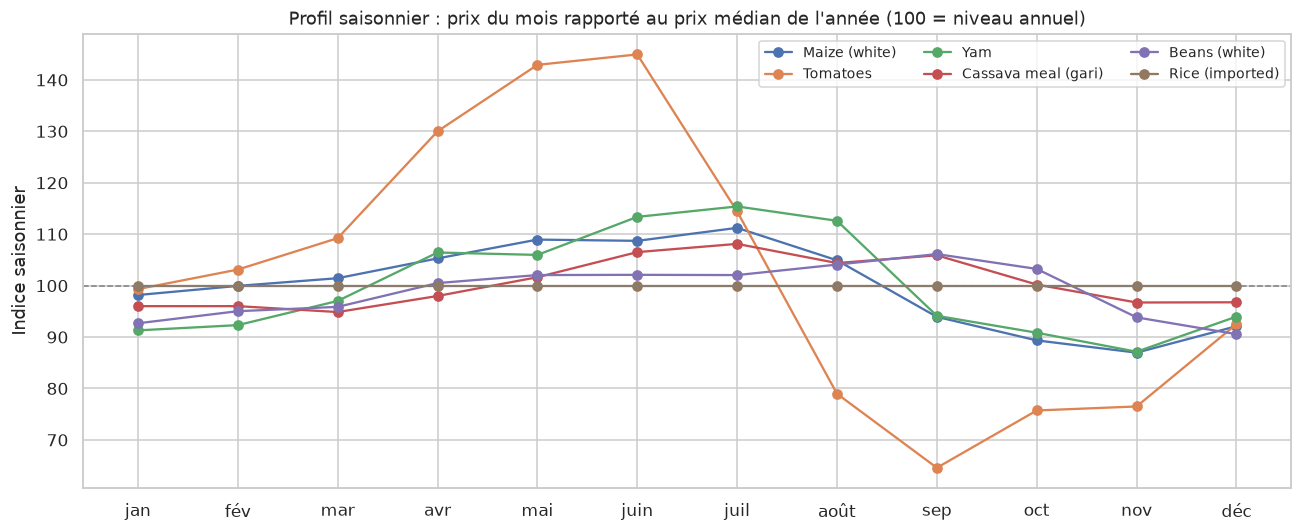

In [21]:
SEASONAL = ["Maize (white)", "Tomatoes", "Yam", "Cassava meal (gari)", "Beans (white)", "Rice (imported)"]
# Prix relatif au niveau moyen de l'année pour neutraliser la tendance
s = STUDY[STUDY["commodity"].isin(SEASONAL)].copy()
s["relatif"] = s["price"] / s.groupby(["commodity", "year"])["price"].transform("median")
season = s.groupby(["commodity", "month"])["relatif"].median().unstack(0)

fig, ax = plt.subplots(figsize=(12, 5))
for c in SEASONAL:
    ax.plot(season.index, 100 * season[c], marker="o", label=c)
ax.axhline(100, color="grey", linestyle="--", linewidth=1)
ax.set_xticks(range(1, 13), ["jan", "fév", "mar", "avr", "mai", "juin", "juil", "août", "sep", "oct", "nov", "déc"])
ax.set(title="Profil saisonnier : prix du mois rapporté au prix médian de l'année (100 = niveau annuel)",
       ylabel="Indice saisonnier")
ax.legend(ncol=3, fontsize=9)
plt.tight_layout(); plt.show()

**Lecture.**
- La **tomate** est le produit le plus saisonnier : son prix monte d'avril à juin, en période de soudure, puis chute fortement d'août à octobre avec l'arrivée des récoltes.
- Le **maïs** et l'**igname** suivent le même calendrier agricole : prix plus élevés au printemps et en été avant les récoltes, plus bas à l'automne.
- Le **haricot** et le **gari** ont un cycle plus modéré, avec un maximum en septembre et un minimum en décembre et janvier.
- Le **riz importé** ne montre aucune saisonnalité, ce qui est cohérent avec un produit qui ne dépend pas des récoltes locales.

Le mois de l'année est donc une variable utile, mais son effet dépend du produit.

### 7.4 Comparaison entre produits

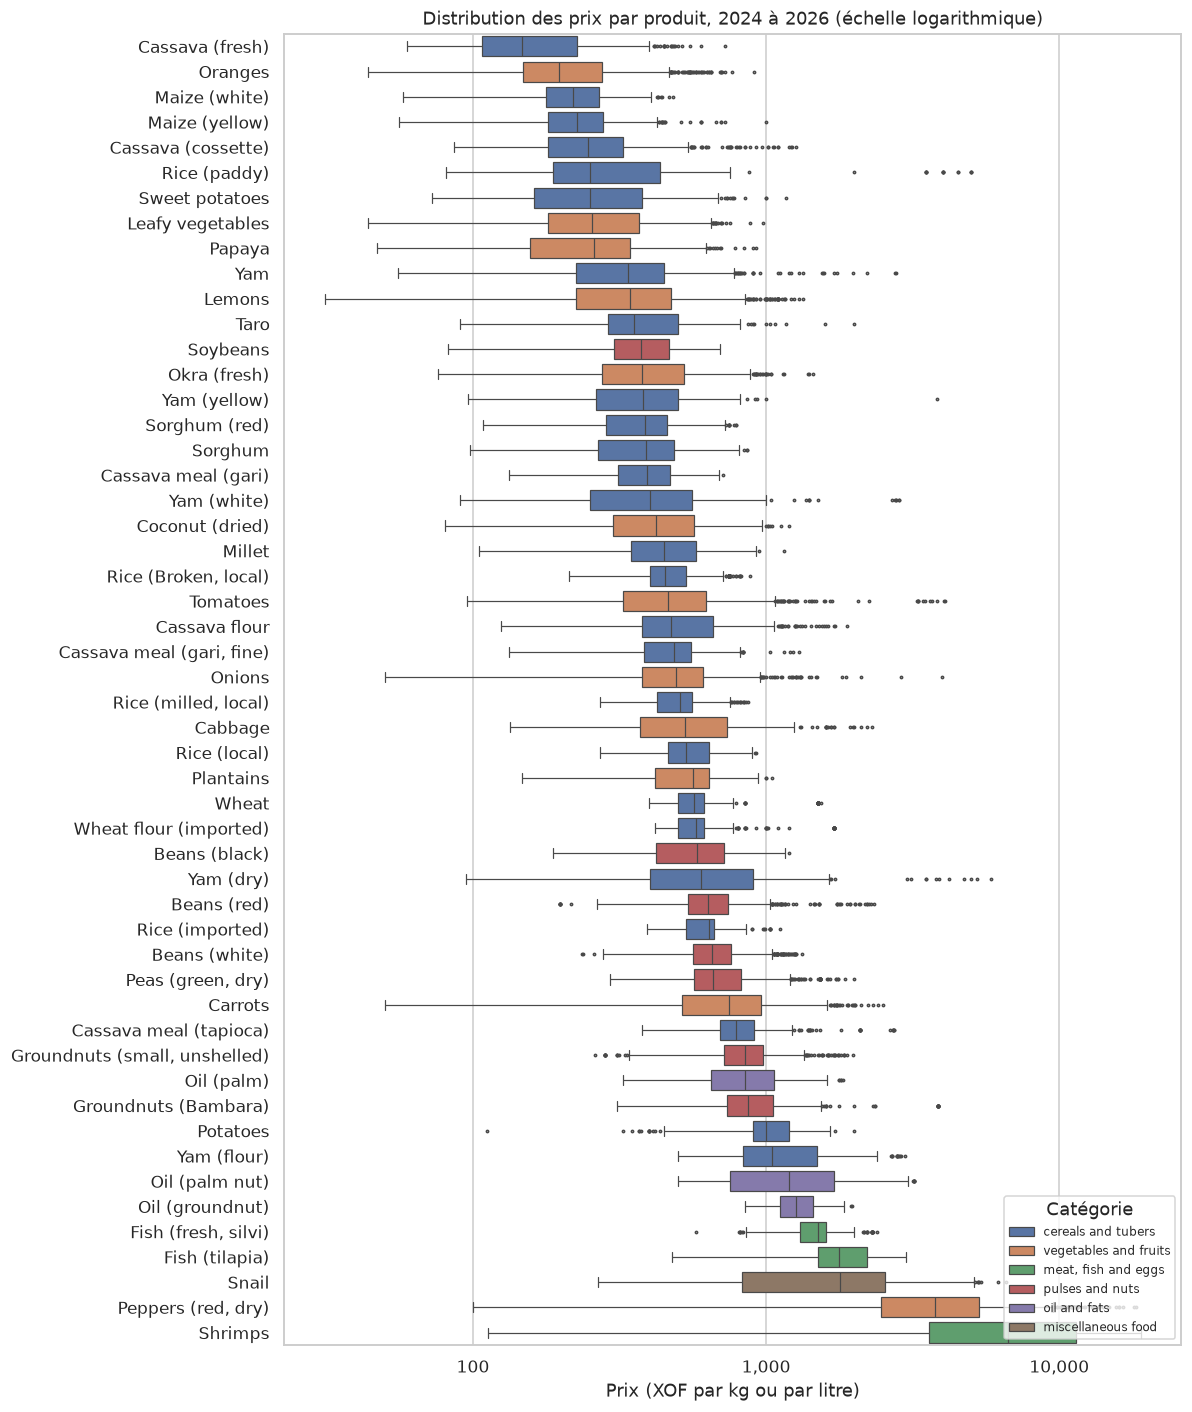

In [22]:
recent = STUDY[(STUDY["year"] >= 2024) & (STUDY["pricetype"] == "Retail")]
order = recent.groupby("commodity")["price"].median().sort_values().index

fig, ax = plt.subplots(figsize=(11, 13))
sns.boxplot(data=recent, y="commodity", x="price", order=order, hue="category",
            dodge=False, fliersize=1.5, linewidth=0.8, ax=ax)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.set(title="Distribution des prix par produit, 2024 à 2026 (échelle logarithmique)", xlabel="Prix (XOF par kg ou par litre)", ylabel="")
ax.legend(title="Catégorie", loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

**Lecture.** Les prix vont de moins de 200 XOF le kilo pour le manioc frais ou le maïs à plus de 8 000 XOF pour les crevettes, soit un rapport de 1 à 40. Le produit est donc de loin le premier déterminant du prix. Les boîtes larges, comme celles des ignames ou du piment, indiquent de fortes différences entre marchés et entre saisons pour un même produit.

### 7.5 Comparaison entre marchés

Comparer directement les prix moyens de deux marchés serait trompeur : un marché qui vend surtout des produits chers paraîtrait cher. On construit donc un **indice de prix relatif**. Pour chaque relevé, on calcule l'écart entre son prix et le prix médian national du même produit, de la même unité et du même mois. On fait ensuite la moyenne de ces écarts par marché. Un indice de +10 % signifie qu'à produit et mois égaux, le marché est 10 % plus cher que la médiane nationale.

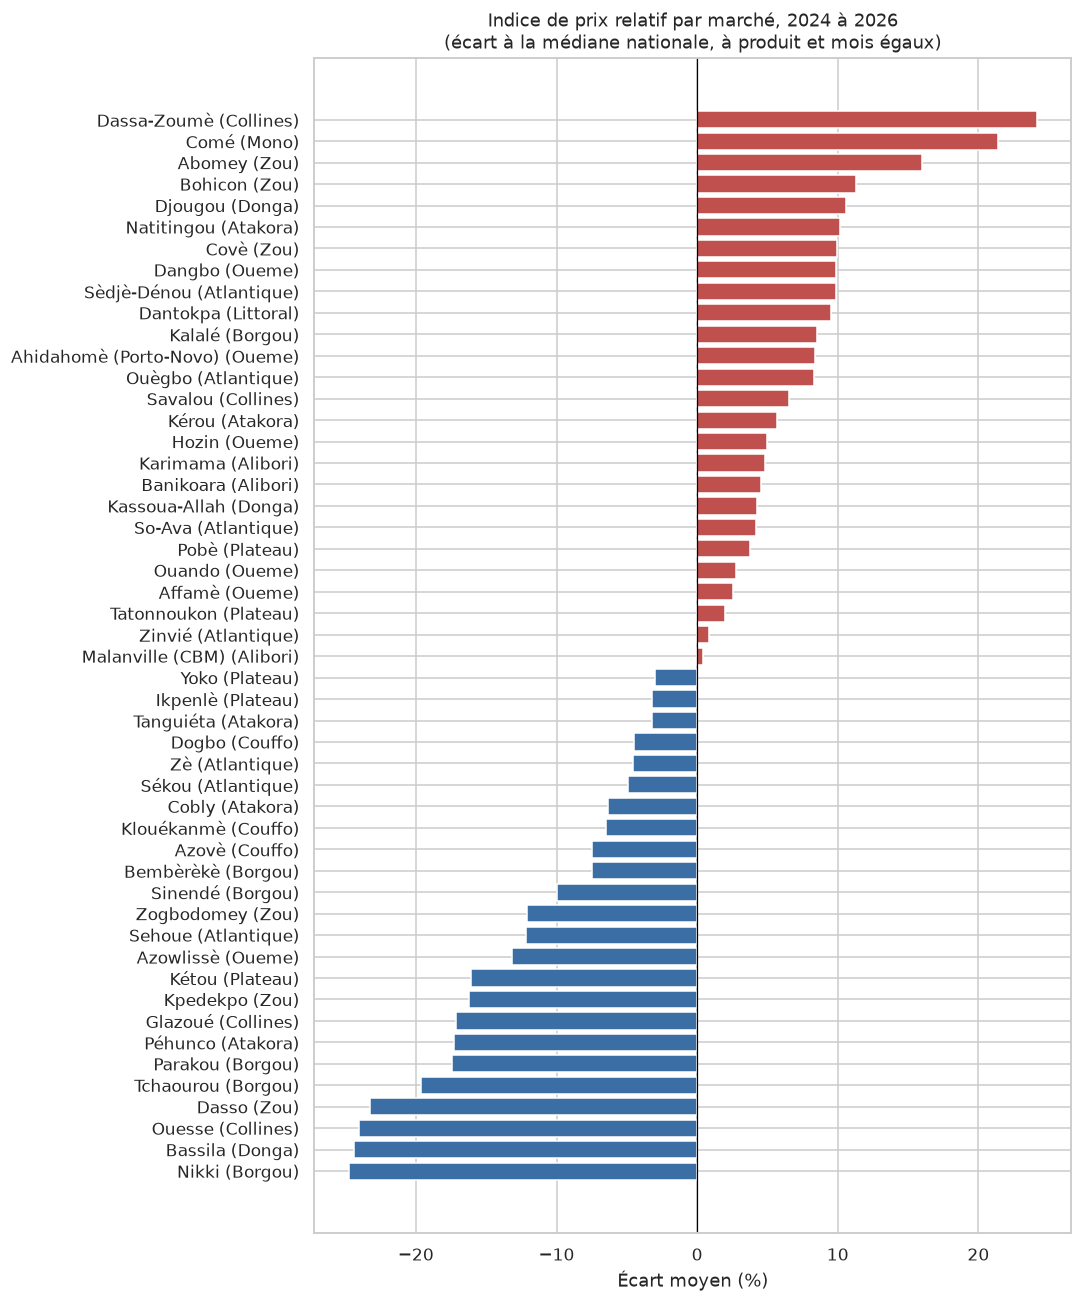

In [23]:
SERIES = ["commodity", "unit", "pricetype", "date"]
STUDY["ecart_log"] = STUDY["log_price"] - STUDY.groupby(SERIES)["log_price"].transform("median")

def relative_index(data, by):
    out = data.groupby(by).agg(indice=("ecart_log", "mean"), releves=("price", "size"),
                               produits=("commodity", "nunique"))
    out["indice_%"] = 100 * (np.exp(out["indice"]) - 1)
    return out.drop(columns="indice").sort_values("indice_%")

recent_study = STUDY[STUDY["year"] >= 2024]
mkt = relative_index(recent_study, ["market", "admin1"]).reset_index()

fig, ax = plt.subplots(figsize=(10, 12))
colors = np.where(mkt["indice_%"] >= 0, "#c0504d", "#3b6ea5")
ax.barh(mkt["market"] + " (" + mkt["admin1"] + ")", mkt["indice_%"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Indice de prix relatif par marché, 2024 à 2026\n(écart à la médiane nationale, à produit et mois égaux)",
       xlabel="Écart moyen (%)", ylabel="")
plt.tight_layout(); plt.show()

In [24]:
print("Marchés les moins chers :"); display(mkt.head(5))
print("Marchés les plus chers :"); display(mkt.tail(5))

Marchés les moins chers :


,market,admin1,releves,produits,indice_%
0,Nikki,Borgou,600,42,-24.78
1,Bassila,Donga,935,46,-24.41
2,Ouesse,Collines,757,37,-24.07
3,Dasso,Zou,748,45,-23.24
4,Tchaourou,Borgou,698,39,-19.66


Marchés les plus chers :


,market,admin1,releves,produits,indice_%
45,Djougou,Donga,727,38,10.56
46,Bohicon,Zou,861,44,11.33
47,Abomey,Zou,1168,52,15.96
48,Comé,Mono,958,46,21.42
49,Dassa-Zoumè,Collines,953,49,24.17


In [25]:
# Écart entre marchés pour quelques produits de base, 2024 à 2026
pivot = (recent_study[recent_study["commodity"].isin(STAPLES)]
           .groupby(["commodity", "market"])["price"].median().unstack(0))
spread = pd.DataFrame({"marche_moins_cher": pivot.idxmin(), "prix_min": pivot.min(),
                       "marche_plus_cher": pivot.idxmax(), "prix_max": pivot.max()})
spread["rapport_max_min"] = spread["prix_max"] / spread["prix_min"]
spread.round(1)

,marche_moins_cher,prix_min,marche_plus_cher,prix_max,rapport_max_min
commodity,,,,,
Beans (white),Parakou,405.00,Kérou,"1,177.40",2.90
Cassava meal (gari),Yoko,182.00,Banikoara,565.00,3.10
Maize (white),Bembèrèkè,146.00,Sèdjè-Dénou,302.00,2.10
Oil (palm),Affamè,600.00,Karimama,"1,500.00",2.50
Rice (imported),Ikpenlè,426.00,Comé,798.00,1.90
Tomatoes,Sinendé,200.00,Tatonnoukon,845.00,4.20
Yam,Kpedekpo,102.80,Zè,"1,567.00",15.30


**Lecture.**
- À produit et mois égaux, l'indice va d'environ -25 % à +24 %. Le marché le plus cher est donc environ 65 % plus cher que le moins cher.
- Les marchés les moins chers sont des marchés ruraux proches des zones de production : Nikki et Tchaourou (Borgou), Bassila (Donga), Ouessè (Collines), Dasso (Zou).
- Les plus chers sont des villes et des marchés de consommation : Dassa-Zoumè, Comé, Abomey, Bohicon et Djougou.
- Un même département peut contenir les deux extrêmes. Dans les Collines, Ouessè est parmi les moins chers et Dassa-Zoumè le plus cher. Dans le Zou, Dasso s'oppose à Abomey et Bohicon.
- Pour un même produit de base, le prix médian varie du simple au double, voire plus, selon le marché. Le rapport de 15 observé sur l'igname est très probablement gonflé par des relevés aberrants.
- Le marché est donc la variable explicative la plus importante après le produit.

### 7.6 Comparaison entre départements

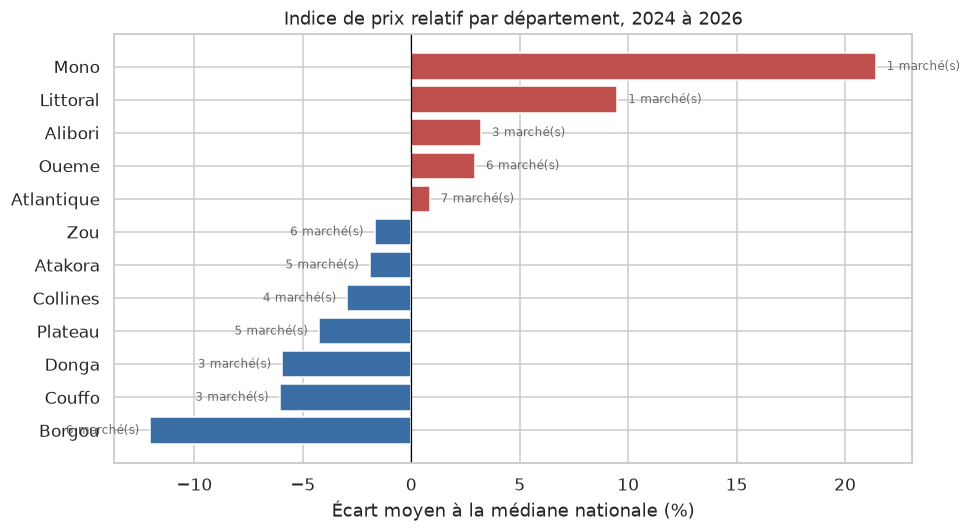

,releves,produits,indice_%,marches
admin1,,,,
Borgou,4449,51,-12.02,6
Couffo,2492,49,-6.06,3
Donga,2507,48,-5.95,3
Plateau,3668,50,-4.26,5
Collines,3841,51,-2.95,4
Atakora,4254,51,-1.90,5
Zou,5297,52,-1.69,6
Atlantique,5114,52,0.85,7
Oueme,4518,46,2.94,6


In [26]:
dep = relative_index(recent_study, "admin1")
dep["marches"] = recent_study.groupby("admin1")["market"].nunique()

fig, ax = plt.subplots(figsize=(9, 5))
colors = np.where(dep["indice_%"] >= 0, "#c0504d", "#3b6ea5")
ax.barh(dep.index, dep["indice_%"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
for y, (v, n) in enumerate(zip(dep["indice_%"], dep["marches"])):
    ax.text(v + (0.5 if v >= 0 else -0.5), y, f"{n} marché(s)", va="center",
            ha="left" if v >= 0 else "right", fontsize=8, color="dimgray")
ax.set(title="Indice de prix relatif par département, 2024 à 2026", xlabel="Écart moyen à la médiane nationale (%)", ylabel="")
plt.tight_layout(); plt.show()
dep

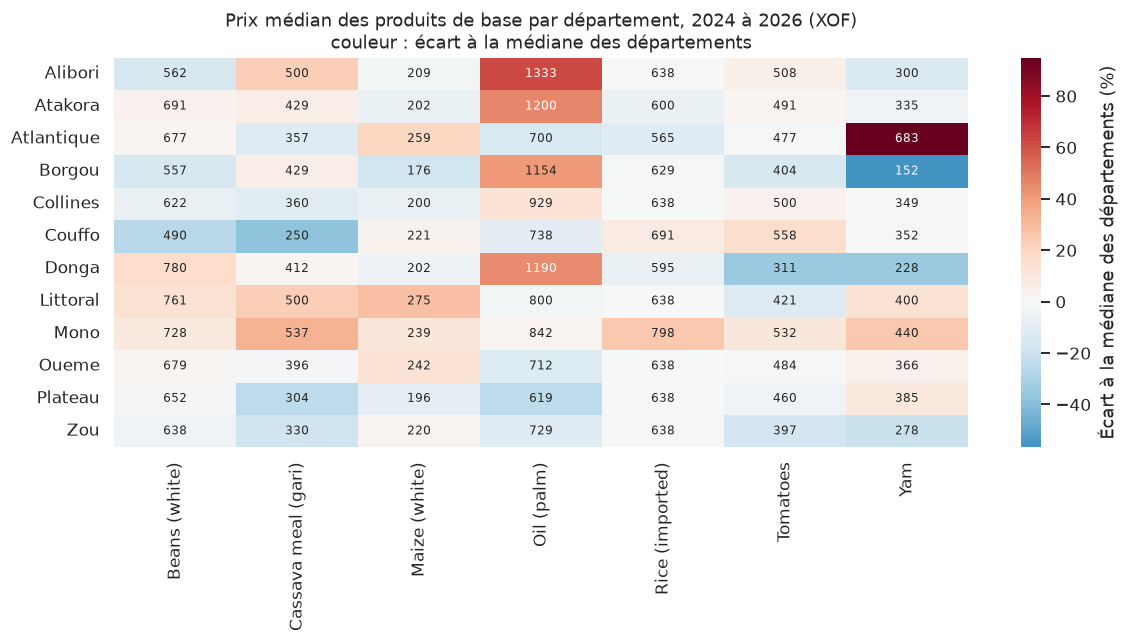

In [27]:
heat = (recent_study[recent_study["commodity"].isin(STAPLES)]
          .groupby(["admin1", "commodity"])["price"].median().unstack())
heat_rel = 100 * (heat / heat.median() - 1)

fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(heat_rel, annot=heat.round(0).astype("Int64"), fmt="", cmap="RdBu_r", center=0,
            cbar_kws={"label": "Écart à la médiane des départements (%)"}, ax=ax, annot_kws={"fontsize": 8})
ax.set(title="Prix médian des produits de base par département, 2024 à 2026 (XOF)\ncouleur : écart à la médiane des départements",
       xlabel="", ylabel="")
plt.tight_layout(); plt.show()

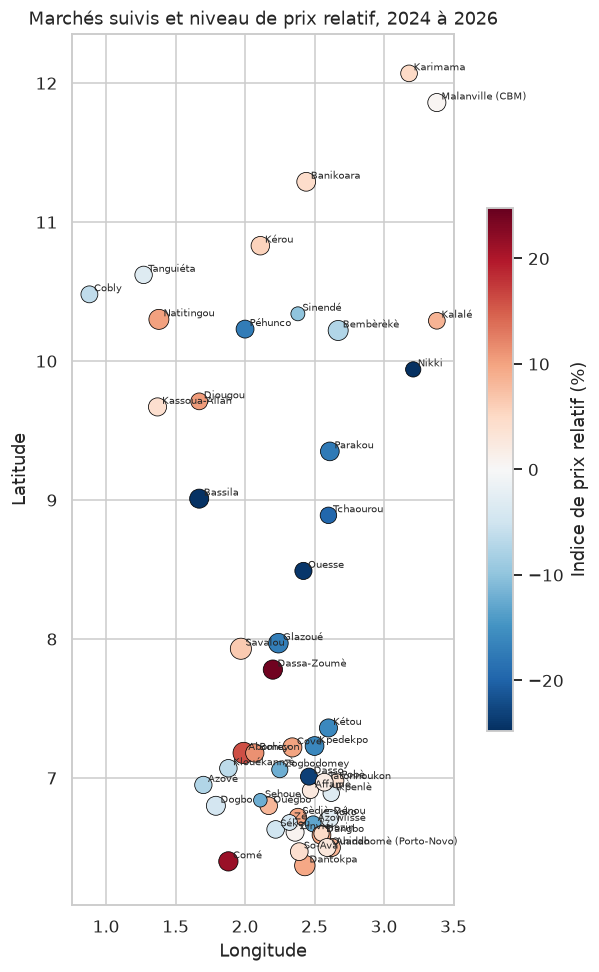

In [28]:
# Carte simple : position des marchés, couleur = indice de prix relatif
geo = (recent_study.groupby(["market", "admin1"])
         .agg(lat=("latitude", "first"), lon=("longitude", "first"), indice=("ecart_log", "mean"), n=("price", "size"))
         .reset_index())
geo["indice_%"] = 100 * (np.exp(geo["indice"]) - 1)

fig, ax = plt.subplots(figsize=(6.5, 9))
lim = geo["indice_%"].abs().max()
sc = ax.scatter(geo["lon"], geo["lat"], c=geo["indice_%"], cmap="RdBu_r", vmin=-lim, vmax=lim,
                s=geo["n"] / 6, edgecolor="black", linewidth=0.5)
for _, r in geo.iterrows():
    ax.annotate(r["market"], (r["lon"], r["lat"]), fontsize=6.5, xytext=(3, 2), textcoords="offset points")
plt.colorbar(sc, ax=ax, label="Indice de prix relatif (%)", shrink=0.6)
ax.set(title="Marchés suivis et niveau de prix relatif, 2024 à 2026", xlabel="Longitude", ylabel="Latitude")
ax.set_aspect("equal")
plt.tight_layout(); plt.show()

**Lecture.**
- Le **Borgou** est nettement le département le moins cher, environ 12 % sous la médiane nationale. C'est une grande zone de production de céréales et d'igname.
- Le **Mono** et le **Littoral** (Cotonou) sont les plus chers. L'Ouémé, l'Alibori et l'Atlantique sont légèrement au-dessus de la médiane.
- Il n'y a pas de simple opposition nord-sud. Le Couffo et le Plateau, au sud, sont moins chers que la médiane, et l'Alibori, au nord, est plus cher.
- Le Littoral et le Mono ne comptent qu'un seul marché suivi chacun : Dantokpa et Comé. Leur indice décrit ce marché, pas tout le département, et doit être lu avec prudence.
- Les écarts entre départements sont plus faibles qu'entre marchés. La commune et le marché sont plus informatifs que le département seul.

## 8. Ce qui explique le prix

Pour orienter la modélisation, on mesure la part de la variance de `log(prix)` expliquée par chaque variable prise seule. C'est un R² simple : 1 moins la variance restante une fois retirée la moyenne de chaque groupe. Le second calcul mesure ce que chaque variable explique **une fois le produit connu**.

In [29]:
def explained(y, groups):
    return 1 - y.groupby(groups).transform(lambda s: s - s.mean()).var() / y.var()

y = STUDY["log_price"]
resid = y - y.groupby(STUDY["commodity"]).transform("mean")
rows = []
for col in ["commodity", "category", "market", "admin2", "admin1", "year", "month", "unit", "pricetype"]:
    rows.append({"variable": col,
                 "R2_seule": explained(y, STUDY[col]),
                 "R2_apres_produit": explained(resid, STUDY[col]) if col != "commodity" else np.nan})
pd.DataFrame(rows).set_index("variable").sort_values("R2_seule", ascending=False)

,R2_seule,R2_apres_produit
variable,,
commodity,0.70,NaN
category,0.23,0.00
unit,0.04,0.00
market,0.03,0.08
admin2,0.03,0.08
year,0.02,0.05
admin1,0.00,0.01
month,0.00,0.00
pricetype,0.00,0.00


In [30]:
# Interaction produit x marché : la plus fine que le modèle puisse apprendre
pm = explained(y, [STUDY["commodity"], STUDY["market"]])
pmy = explained(y, [STUDY["commodity"], STUDY["market"], STUDY["year"]])
print(f"Produit x marché        : R2 = {pm:.3f}")
print(f"Produit x marché x année: R2 = {pmy:.3f}")

Produit x marché        : R2 = 0.863
Produit x marché x année: R2 = 0.939


In [31]:
# Couverture produit x marché : toutes les combinaisons ne sont pas observées
combos = STUDY.groupby(["market", "commodity"]).size()
print("Combinaisons marché x produit observées :", len(combos), "sur", STUDY["market"].nunique() * STUDY["commodity"].nunique())

# Simulation d'un découpage temporel : combien de relevés récents portent sur une combinaison jamais vue avant ?
for cut in ["2025-01-01", "2025-07-01"]:
    c = pd.Timestamp(cut)
    seen = set(map(tuple, STUDY.loc[STUDY["date"] < c, ["market", "commodity"]].values))
    after = STUDY[STUDY["date"] >= c]
    unseen = sum(tuple(v) not in seen for v in after[["market", "commodity"]].values)
    print(f"Coupure {cut} : {len(after)} relevés de test, dont {unseen} ({100 * unseen / len(after):.1f} %) sur une combinaison inédite")

Combinaisons marché x produit observées : 2312 sur 2650
Coupure 2025-01-01 : 22224 relevés de test, dont 316 (1.4 %) sur une combinaison inédite


Coupure 2025-07-01 : 12759 relevés de test, dont 49 (0.4 %) sur une combinaison inédite


**Lecture.**
- Le **produit** explique à lui seul environ 70 % de la variance de `log(prix)`. La catégorie en explique beaucoup moins : elle regroupe des produits aux prix très différents.
- Une fois le produit connu, le **marché** et l'**année** sont les variables les plus utiles. Le département et le mois n'apportent qu'un faible complément en moyenne. L'effet du mois est réel mais dépend du produit, comme le montre la section 7.3.
- La combinaison produit, marché et année explique l'essentiel de la variance. Un modèle à base d'arbres, capable d'apprendre ces interactions, est donc adapté.
- Avec un découpage temporel, une petite partie des relevés de test portera sur des combinaisons marché et produit jamais vues à l'entraînement. Ce sont les cas où l'estimation sera la moins fiable, comme le signale déjà la page Batch CSV de l'application.

## 9. Conclusions métier et recommandations

### Principales observations

1. **Des données fiables mais concentrées sur 2019 à 2026.** Le jeu ne présente ni valeur manquante ni doublon, et ses référentiels sont cohérents. Avant 2019, le suivi est trop partiel pour être représentatif.
2. **Le produit fait le prix.** Les prix vont de 1 à 40 selon le produit. Toute comparaison doit se faire à produit, unité et type de prix égaux.
3. **Une forte hausse en 2021 et 2022, puis en 2024.** Les produits de base ont pris entre 30 % et 70 % entre 2020 et leur pic. Le maïs et le gari ont nettement reculé en 2025 et début 2026.
4. **Une saisonnalité marquée pour les produits locaux.** La tomate, le maïs et l'igname sont plus chers avant les récoltes et moins chers après. Le riz importé n'est pas saisonnier.
5. **Des écarts géographiques importants.** À produit et mois égaux, le marché le plus cher l'est environ 65 % de plus que le moins cher. Les marchés ruraux proches des zones de production sont les moins chers, les villes et marchés de consommation les plus chers. Le Borgou est le département le moins cher, le Mono et le Littoral les plus chers. Les écarts entre marchés sont plus forts que les écarts entre départements.
6. **Quelques prix aberrants.** Moins de 1 % des relevés sont atypiques. Certains sont manifestement des erreurs de saisie et doivent être vérifiés avant usage métier.

### Intérêt pour les utilisateurs

- Un ménage ou un commerçant peut savoir si le prix observé sur son marché est dans la norme pour la saison.
- Une organisation de sécurité alimentaire peut repérer les marchés et les mois où les prix sont durablement au-dessus de la normale nationale.
- Le choix du marché d'achat et du moment d'achat peut faire varier le prix d'un même produit de façon importante.

### Recommandations pour la modélisation (personne 2)

| Sujet | Recommandation |
|---|---|
| Découpage | Fusionner `train` et `test`, puis découper par date : entraînement avant une date de coupure, validation et test sur les mois suivants. |
| Période | Entraîner en priorité sur 2019 et après. Tester si l'ajout des années antérieures améliore ou dégrade le modèle. |
| Cible | Prédire `log(prix)` puis reconvertir en XOF. Mettre `LOG_TARGET = True` dans l'application si ce choix est retenu. |
| Variables à garder | `commodity`, `unit`, `pricetype`, `market`, `admin2`, `admin1`, `latitude`, `longitude`, `category`, `year`, `month`. |
| Variables à exclure | `usdprice` (fuite de cible), `currency`, `priceflag`, `esa_source`, `esa_processed` (constantes), `market_id` et `commodity_id` (redondants). |
| Modèle | Privilégier un modèle à base d'arbres (forêt aléatoire, gradient boosting) qui capte les interactions produit, marché et saison. |
| Métriques | Suivre la MAE et la RMSE en XOF, et aussi une erreur relative (MAPE), car une erreur de 100 XOF n'a pas le même poids sur le maïs et sur les crevettes. |
| Valeurs extrêmes | Ne pas les supprimer par défaut. Comparer les scores avec et sans les relevés dont le score robuste dépasse 5. |
| Limites | Les modèles à arbres ne prolongent pas les tendances : au-delà de février 2026, l'estimation reflète le niveau récent. Les combinaisons marché et produit inédites sont moins fiables. |